In [1]:
!pip install spacy

In [2]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     -------- ------------------------------- 2.6/12.8 MB 15.6 MB/s eta 0:00:01
     --------------------------- ------------ 8.7/12.8 MB 23.6 MB/s eta 0:00:01
     ------------------------------------ -- 12.1/12.8 MB 21.0 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 16.0 MB/s  0:00:00
[+] Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [4]:
import spacy
nlp = spacy.load("en_core_web_sm")

# Basic NER

In [5]:
text = "Elon Musk co-founded Tesla, which is now based in Texas since 2021."
doc = nlp(text)
for ent in doc.ents:
    print(ent.text, ent.label_)

Tesla ORG
Texas GPE
2021 DATE


# Person Identification

In [6]:
text ="Satya Nadella leading Microsoft from its headquarters in Redmond, Washington."
doc = nlp(text)
for ent in doc.ents:
    print(ent.text, ent.label_)

Satya Nadella PERSON
Microsoft ORG
Redmond GPE
Washington GPE


# Organizations

In [7]:
text = "OpenAI launched ChatGPT, while Google introduced Gemini to compete in the AI market."
doc = nlp(text)
for ent in doc.ents:
    print(ent.text, ent.label_)

OpenAI PERSON
Google ORG
Gemini GPE
AI GPE


# Locations

In [8]:
text = "ISRO successfully launched Chandrayaan-3 from Sriharikota to land on the Moon."
doc = nlp(text)
for ent in doc.ents:
    print(ent.text, ent.label_)

Sriharikota LOC
Moon PERSON


# Percentage

In [9]:
text = "The RBI increased the repo rate by 25 basis points to 6.75% during the policy review."
doc = nlp(text)
for ent in doc.ents:
    print(ent.text, ent.label_)

RBI ORG
25 CARDINAL
6.75% PERCENT


# Extract only person entites .

In [10]:
text = """
Elon Musk leads Tesla and SpaceX.
Mark Zuckerberg is the founder of Meta.
Jensen Huang runs Nvidia.
"""
doc = nlp(text)
for ent in doc.ents:
    if ent.label_ == "PERSON":
        print(ent.text)

Elon Musk
Tesla
Mark Zuckerberg
Jensen Huang


# Extract Organization

In [11]:
text = """
OpenAI created ChatGPT and GPT-4.
Anthropic is developing the Claude models.
Perplexity is revolutionizing web search.
"""
doc = nlp(text)
for ent in doc.ents:
    if ent.label_ == "ORG":
        print(ent.text)

Claude


# Extract all the entity types

In [13]:
text = """
Mark Zuckerberg went to Tokyo on 15 March 2026.
Meta invested $10 billion in advanced robotics research.
"""
doc = nlp(text)
for ent in doc.ents:
    print(
        "Entity:", ent.text,
        "Label:", ent.label_,
        "Meaning:", spacy.explain(ent.label_)
    )

Entity: Mark Zuckerberg Label: PERSON Meaning: People, including fictional
Entity: Tokyo Label: GPE Meaning: Countries, cities, states
Entity: 15 March 2026 Label: DATE Meaning: Absolute or relative dates or periods
Entity: Meta Label: ORG Meaning: Companies, agencies, institutions, etc.
Entity: $10 billion Label: MONEY Meaning: Monetary values, including unit


# NER Visualization with displacy

In [14]:
import spacy
from spacy import displacy
nlp = spacy.load("en_core_web_sm")
text = "Elon Musk announced that SpaceX will launch a new rocket from Florida on 20 November 2026."
doc = nlp(text)
displacy.render(doc, style="ent", jupyter=True)

# NER Frequency Visualization

Counter({'GPE': 3, 'PERSON': 2, 'DATE': 2, 'MONEY': 1, 'ORG': 1, 'CARDINAL': 1})


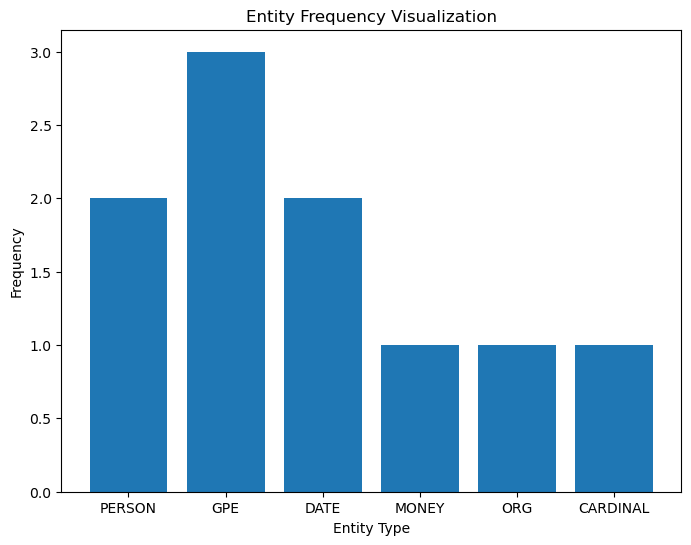

In [15]:
import spacy
from collections import Counter
import matplotlib.pyplot as plt

nlp = spacy.load("en_core_web_sm")

text = """
Elon Musk announced that SpaceX will launch a new rocket from Florida on 20 November 2026. 
The entire mission is estimated to cost around $150 million.
Meanwhile, Sundar Pichai mentioned that Google will expand its AI operations in Tokyo by next year, hiring 500 new engineers.
"""

doc = nlp(text)
entity_counts = Counter(
    ent.label_ for ent in doc.ents
)
print(entity_counts)
plt.figure(figsize=(8, 6))
plt.bar(entity_counts.keys(), entity_counts.values())
plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.title("Entity Frequency Visualization")
plt.show()

# Create an NER DataFrame

In [16]:
import spacy
import pandas as pd
nlp = spacy.load("en_core_web_sm")
text = """
Jensen Huang announced that Nvidia will acquire a startup in London on 12 March 2026. 
The deal is valued at $1.5 billion, which is 15% higher than expected. 
This move will create 450 new jobs in the United Kingdom.
"""
doc = nlp(text)
data = []
for ent in doc.ents:
  data.append({
      "Entity": ent.text,
      "Label": ent.label_,
      "Description": spacy.explain(ent.label_)
  })
df = pd.DataFrame(data)
print(df)

               Entity     Label                                   Description
0        Jensen Huang    PERSON                   People, including fictional
1              Nvidia       GPE                     Countries, cities, states
2              London       GPE                     Countries, cities, states
3       12 March 2026      DATE         Absolute or relative dates or periods
4        $1.5 billion     MONEY               Monetary values, including unit
5                 15%   PERCENT                     Percentage, including "%"
6                 450  CARDINAL  Numerals that do not fall under another type
7  the United Kingdom       GPE                     Countries, cities, states


# Complete NER Program With Visualization
# The combines NER extraction + Frequency analysis +Visualization +displacy

Named Entities
----------------------------------------
Sam Altman          PERSON    People, including fictional
OpenAI              ORG       Companies, agencies, institutions, etc.
San Francisco       GPE       Countries, cities, states
14 December 2026    DATE      Absolute or relative dates or periods
$200 million        MONEY     Monetary values, including unit
Jensen Huang        PERSON    People, including fictional
Nvidia              ORG       Companies, agencies, institutions, etc.
35%                 PERCENT   Percentage, including "%"
5,000               CARDINAL  Numerals that do not fall under another type

Entity Frequency:
Counter({'PERSON': 2, 'ORG': 2, 'GPE': 1, 'DATE': 1, 'MONEY': 1, 'PERCENT': 1, 'CARDINAL': 1})


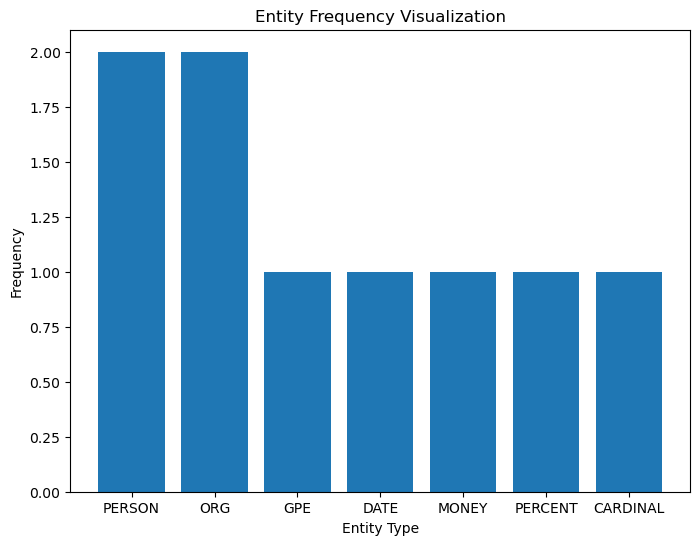

In [17]:
import spacy
from spacy import displacy
from collections import Counter
import matplotlib.pyplot as plt

#Text
text = """
Sam Altman announced that OpenAI will launch its new model from San Francisco on 14 December 2026. 
The organization invested $200 million into this next-generation deep learning cluster. 
Meanwhile, Jensen Huang stated that Nvidia expects a 35% growth in semiconductor supply, benefiting over 5,000 global tech enterprises.
"""

# Process text
doc = nlp(text)

#Display entities
print("Named Entities")
print("-" *40)

for ent in doc.ents:
    print(
       f"{ent.text:20}"
       f"{ent.label_:10}"
       f"{spacy.explain(ent.label_)}"
    )
# Count entity types
entity_counts = Counter(
    ent.label_ for ent in doc.ents
)

print("\nEntity Frequency:")
print(entity_counts)

# Bar Chart

plt.figure(figsize=(8, 6))
plt.bar(entity_counts.keys(), entity_counts.values())
plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.title("Entity Frequency Visualization")
plt.show()

# Enity visualization

displacy.render(doc, style="ent", jupyter=True)